# Python DA Assignment 2 – Data Visualization

## 1. Loading the Taxis Dataset

In [1]:
# Import seaborn library
import seaborn as sns

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:
# Display dataset information
df.info()

# Check the number of rows and columns
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


(6433, 14)

## 2. Handling Missing Values

In [3]:
# Check missing values in each column
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [4]:
# Identify columns containing missing values
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [5]:
# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=['number']).columns
categorical_cols = df.select_dtypes(include=['object', 'category', 'str']).columns

# Fill numerical missing values with median
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Remove rows with missing critical values
df = df.dropna(subset=['pickup', 'fare', 'distance'])

# Check missing values again
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [6]:
# Display first five rows after cleaning
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


## 3. Visualizations using Matplotlib/Pandas Plot

### 3.1 Line Chart – Fare Over Time

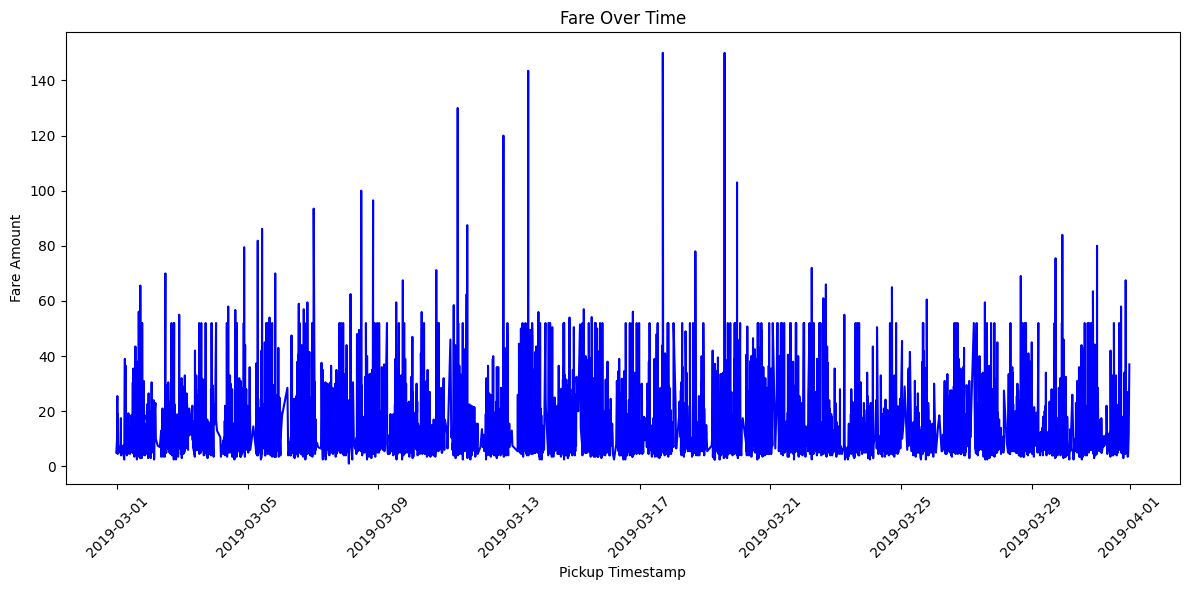

In [7]:
# Import matplotlib and Pandas
import pandas as pd
import matplotlib.pyplot as plt

# Convert pickup column into datetime format
df['pickup'] = pd.to_datetime(df['pickup'])

# Sort data based on pickup timestamp
df = df.sort_values(by='pickup')

# Create a line chart
plt.figure(figsize=(12, 6))

plt.plot(df['pickup'], df['fare'], color='blue')

# Add chart title and labels
plt.title('Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare Amount')

# Rotate x-axis labels
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()

### 3.2 Bar Chart – Total Fare by Pickup Borough

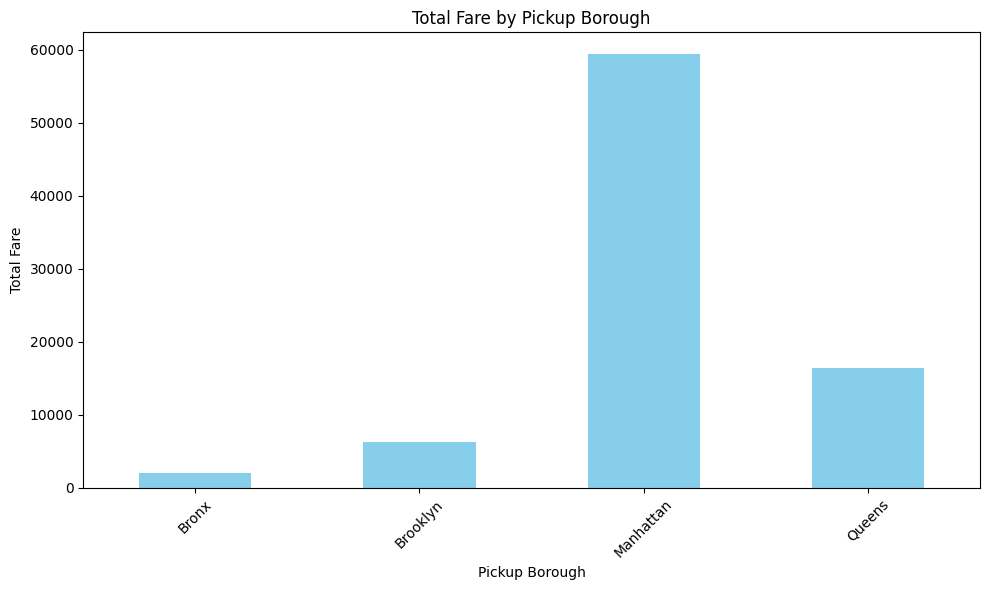

In [8]:
# Group data by pickup_borough and calculate total fare
borough_fare = df.groupby('pickup_borough', observed=True)['fare'].sum()

# Create a bar chart
plt.figure(figsize=(10, 6))

borough_fare.plot(kind='bar', color='skyblue')

# Add chart title and labels
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

# Rotate x-axis labels
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()

### 3.3 Pie Chart – Distribution of Trips by Payment Method

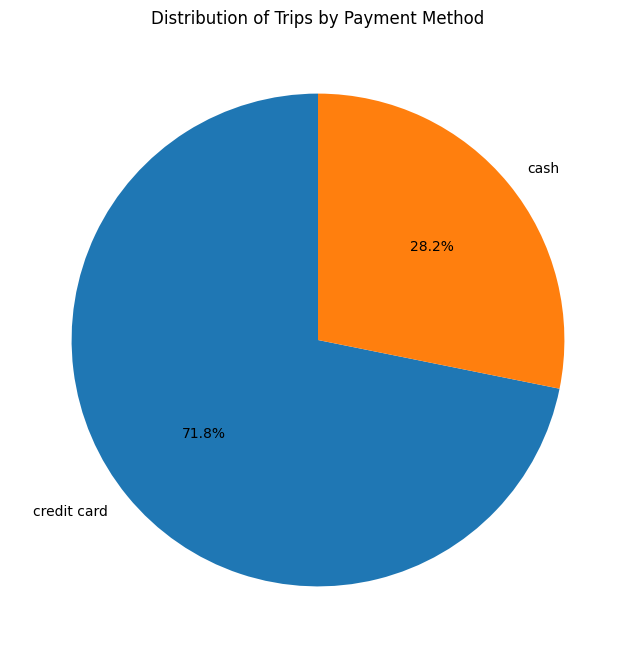

In [9]:
# Count trips based on payment method
payment_counts = df['payment'].value_counts()

# Create a pie chart
plt.figure(figsize=(8, 8))

plt.pie(payment_counts, labels=payment_counts.index,
        autopct='%1.1f%%', startangle=90)

# Add chart title
plt.title('Distribution of Trips by Payment Method')

# Display the chart
plt.show()

### 3.4 Histogram – Distribution of Distance

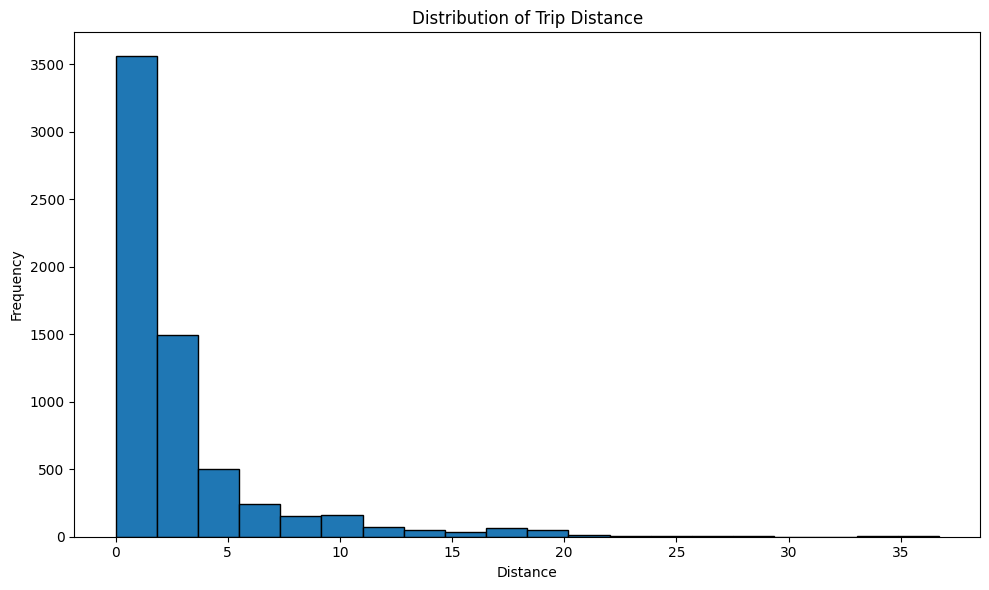

In [10]:
# Create a histogram for distance
plt.figure(figsize=(10, 6))

plt.hist(df['distance'], bins=20, edgecolor='black')

# Add chart title and labels
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

# Display the chart
plt.tight_layout()
plt.show()

### 3.5 Box Plot – Distribution of Tip Amounts by Pickup Borough

<Figure size 1000x600 with 0 Axes>

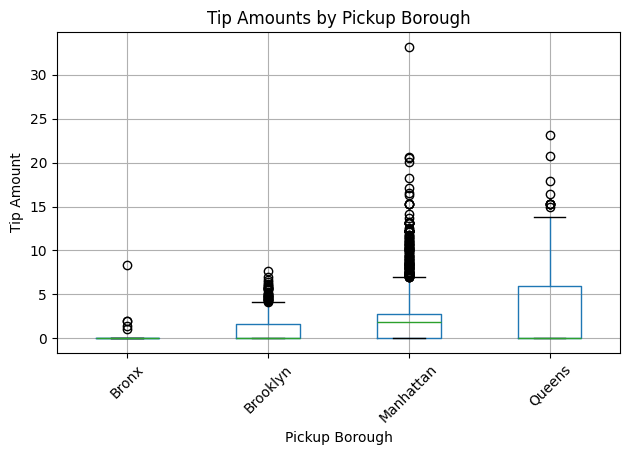

In [11]:
# Create a box plot for tip amounts by pickup borough
plt.figure(figsize=(10, 6))

df.boxplot(column='tip', by='pickup_borough')

# Add chart title and labels
plt.title('Tip Amounts by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

# Display the chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Visualizations using Seaborn

### 4.1 Count Plot – Number of Trips by Pickup Borough

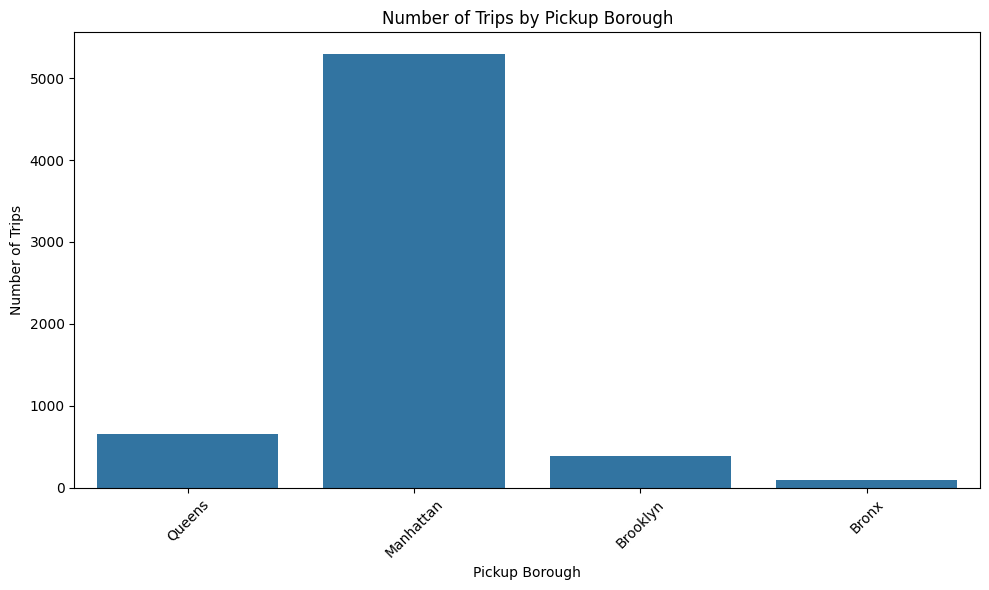

In [12]:
# Create a count plot
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='pickup_borough')

# Add chart title and labels
plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

# Display the chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.2 Scatter Plot – Relationship Between Distance and Fare

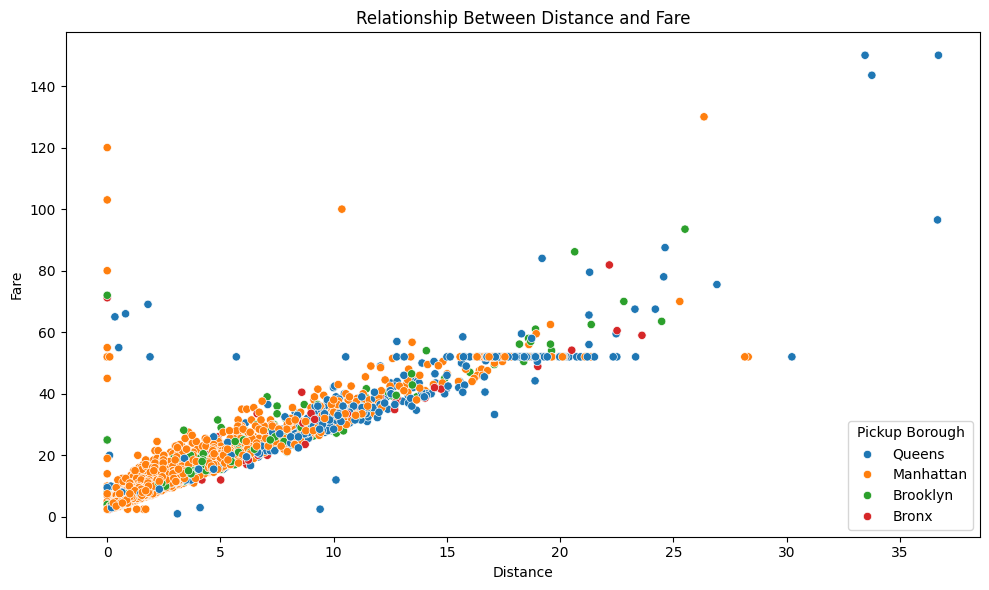

In [13]:
# Create a scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='distance', y='fare',
                hue='pickup_borough')

# Add chart title and labels
plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')

# Display the legend
plt.legend(title='Pickup Borough')

# Display the chart
plt.tight_layout()
plt.show()

### 4.3 Heatmap – Correlation Between Numerical Variables

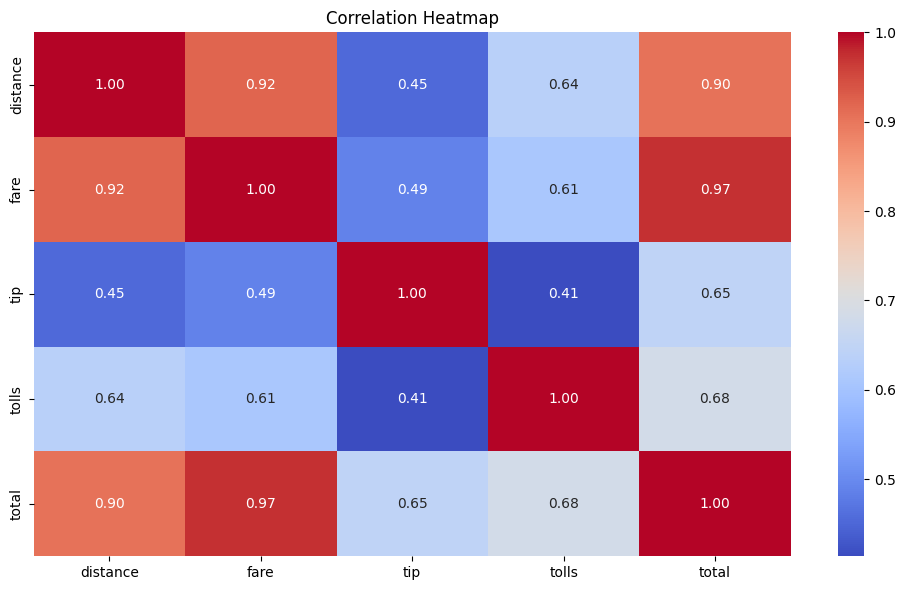

In [14]:
# Select numerical columns
numerical_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

# Create a heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm',
            fmt='.2f')

# Add chart title
plt.title('Correlation Heatmap')

# Display the chart
plt.tight_layout()
plt.show()

### 4.4 Pair Plot – Pairwise Relationships Between Numerical Variables

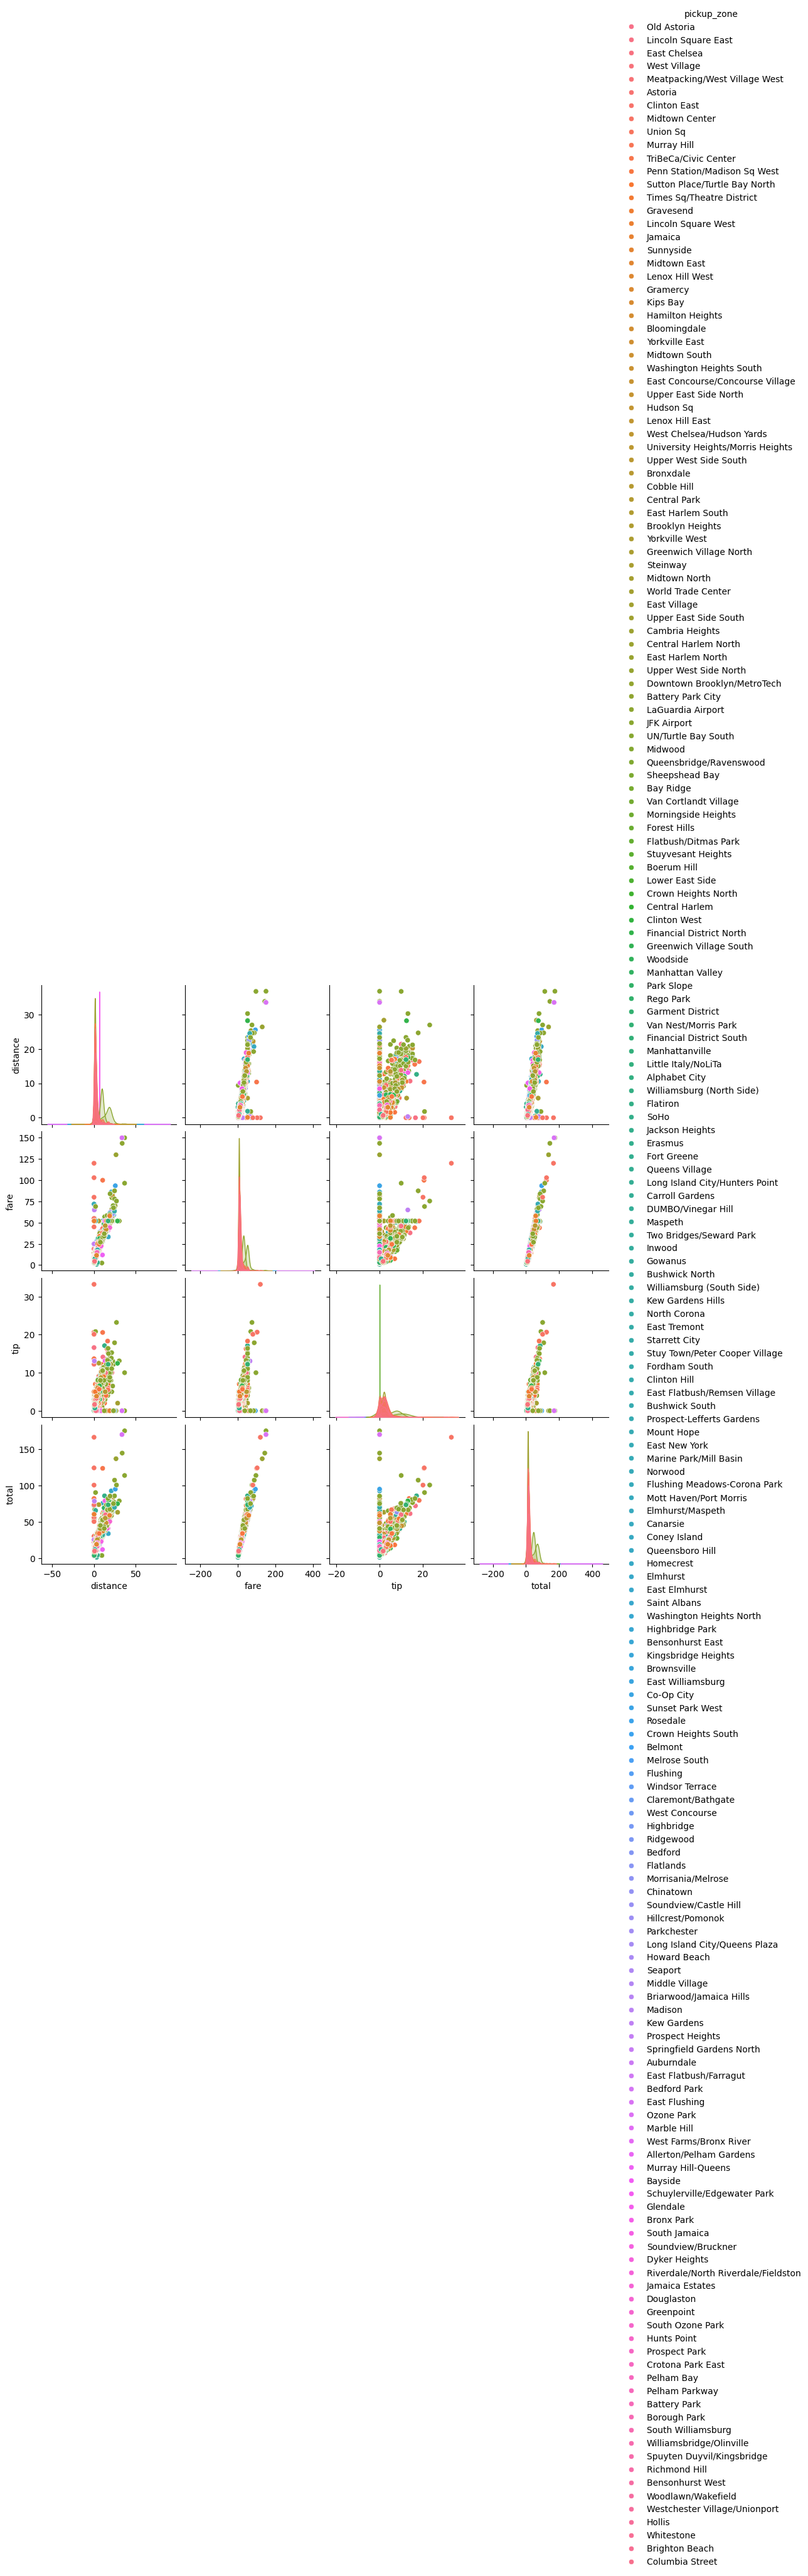

In [16]:
# Select numerical columns for pair plot
pair_data = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna()

# Create a pair plot
sns.pairplot(
    pair_data,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

# Display the plot
plt.show()

### 4.5 Violin Plot – Distribution of Fare by Payment Method

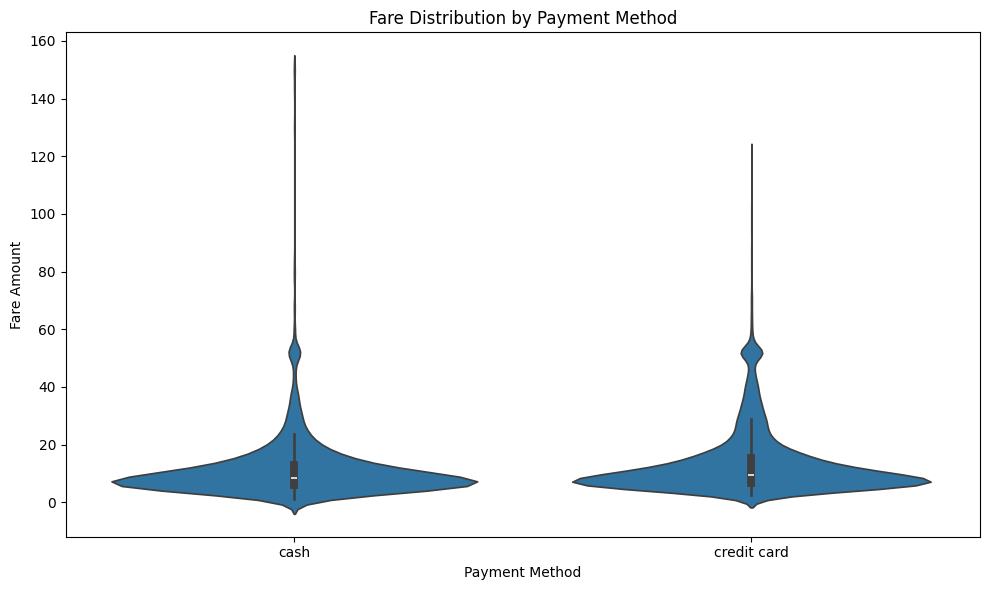

In [22]:
# Create a violin plot
plt.figure(figsize=(10, 6))

sns.violinplot(data=df, x='payment', y='fare')

# Add chart title and labels
plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount')

# Display the chart
plt.tight_layout()
plt.show()